# Liver Patient Disease Prediction

## Business Case:

#### To find the prediction of whether a patient is suffering from Liver disease or not

# Task 1: Prepare a comoplete data analysis report on the given data: 

In [1]:
# Importing libraries

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# loading data:

In [4]:
data = pd.read_csv(r"C:\Users\USER\Datamites Projects\liver_app\Data\Indian Liver Patient Dataset (ILPD).csv", low_memory = False, header = None)
data
#C:\Users\USER\Datamites Projects\Project 3\Data

,0,1,2,3,4,5,6,7,8,9,10
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [5]:
# Adding column names to the given dataset

In [6]:
data.columns = ['Age','Gender','Total Bilirubin','Direct Bilirubin','Alkaline Phosphotase','Alamine Aminotransferase',
               'Aspartate Aminotransferase','Total Protiens','Albumin','Albumin and Globulin','Target']
data

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin,Target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [7]:
data.head()

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin,Target
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [8]:
data.tail()

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin,Target
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1
582,38,Male,1.0,0.3,216,21,24,7.3,4.4,1.50,2


### Basic Checks:

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total Bilirubin             583 non-null    float64
 3   Direct Bilirubin            583 non-null    float64
 4   Alkaline Phosphotase        583 non-null    int64  
 5   Alamine Aminotransferase    583 non-null    int64  
 6   Aspartate Aminotransferase  583 non-null    int64  
 7   Total Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin and Globulin        579 non-null    float64
 10  Target                      583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


In [10]:
data.shape

(583, 11)

In [11]:
pd.set_option('display.max_columns',None)

In [12]:
data.nunique()

Age                            72
Gender                          2
Total Bilirubin               113
Direct Bilirubin               80
Alkaline Phosphotase          263
Alamine Aminotransferase      152
Aspartate Aminotransferase    177
Total Protiens                 58
Albumin                        40
Albumin and Globulin           69
Target                          2
dtype: int64

In [13]:
data.columns

Index(['Age', 'Gender', 'Total Bilirubin', 'Direct Bilirubin',
       'Alkaline Phosphotase', 'Alamine Aminotransferase',
       'Aspartate Aminotransferase', 'Total Protiens', 'Albumin',
       'Albumin and Globulin', 'Target'],
      dtype='object')

In [14]:
for i in data:
    print(data[i].value_counts())
    print('-----------------------------------------------------------------------------------------')

Age
60    34
45    25
50    23
42    21
38    21
      ..
78     1
11     1
67     1
10     1
90     1
Name: count, Length: 72, dtype: int64
-----------------------------------------------------------------------------------------
Gender
Male      441
Female    142
Name: count, dtype: int64
-----------------------------------------------------------------------------------------
Total Bilirubin
0.8     91
0.7     77
0.9     57
0.6     46
1.0     28
        ..
14.5     1
18.5     1
23.2     1
22.6     1
15.0     1
Name: count, Length: 113, dtype: int64
-----------------------------------------------------------------------------------------
Direct Bilirubin
0.2     194
0.1      63
0.3      51
0.8      22
0.4      21
       ... 
3.3       1
11.4      1
2.6       1
3.9       1
13.7      1
Name: count, Length: 80, dtype: int64
-----------------------------------------------------------------------------------------
Alkaline Phosphotase
198    11
215    11
298    11
195    10
190    10
    

In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total Bilirubin             583 non-null    float64
 3   Direct Bilirubin            583 non-null    float64
 4   Alkaline Phosphotase        583 non-null    int64  
 5   Alamine Aminotransferase    583 non-null    int64  
 6   Aspartate Aminotransferase  583 non-null    int64  
 7   Total Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin and Globulin        579 non-null    float64
 10  Target                      583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


In [16]:
data.describe()

,Age,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin,Target
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


In [17]:
data.describe(include = object)

,Gender
count,583
unique,2
top,Male
freq,441


In [18]:
data.isnull().sum()

Age                           0
Gender                        0
Total Bilirubin               0
Direct Bilirubin              0
Alkaline Phosphotase          0
Alamine Aminotransferase      0
Aspartate Aminotransferase    0
Total Protiens                0
Albumin                       0
Albumin and Globulin          4
Target                        0
dtype: int64

In [19]:
data['Target'].value_counts()

Target
1    416
2    167
Name: count, dtype: int64

In [20]:
data.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
578    False
579    False
580    False
581    False
582    False
Length: 583, dtype: bool

In [21]:
data.duplicated().sum()

np.int64(13)

In [22]:
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", data.shape)
data['Target'].value_counts()

Duplicate rows: 13
Shape after removing duplicates: (570, 11)


Target
1    406
2    164
Name: count, dtype: int64

### Domain Analysis:

##### Age: Age of the Patient

##### Gender: Gender of the Patient

##### Total Bilirubin: It is the yellow pigment produced during the breakdown of red blood cells. Elevated levels of total bilirubin in the blood can indicate liver problems

##### Direct Bilirubin: Direct bilirubin refers to the conjugated form of bilirubin that is excreted from the liver into the bile. ELevated levels of direct bilirubin can be an indication of liver diseases or bile duct obstruction.

##### Alkakine Phosphatase: ALP is an enzyme. Elevated levels of ALP in the blood can indicate liver disorders

##### Alamine Aminotransferase: ALT is an enzyme found primarily in liver, Increased levels of LAT can indicate liver damage.

##### Asparatet Aminotransferase: AST is an enxyme, Elevated levels of AST can indicate liver damage, heart problems and muscle injury.

##### Total Protiens: It refers to the total amount of protiens present in the blood, inlucinding albumin and globulins. Abnormal levels of total protiens can indicate various medical conditions, including liver or kidney diseases

##### Albumin: It is a protien synthesized by the liver. Low levels of albumin in the blood can be indicate of liver disease or malfunction.

##### Target: The patient has the disease or not

## EDA (EXPLORATORY DATA ANALYSIS):

### Univariate Analysis:

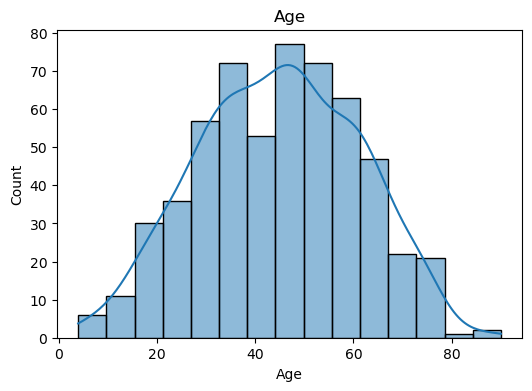

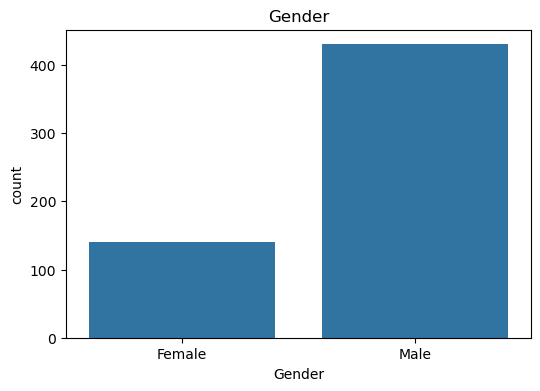

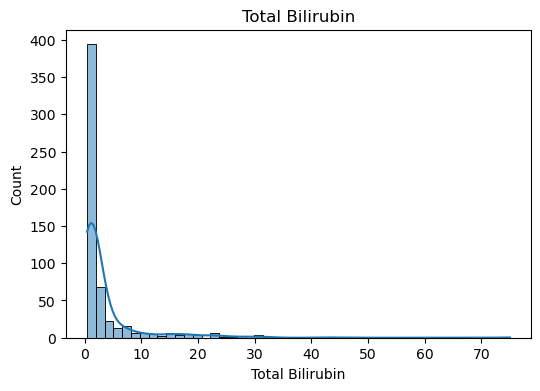

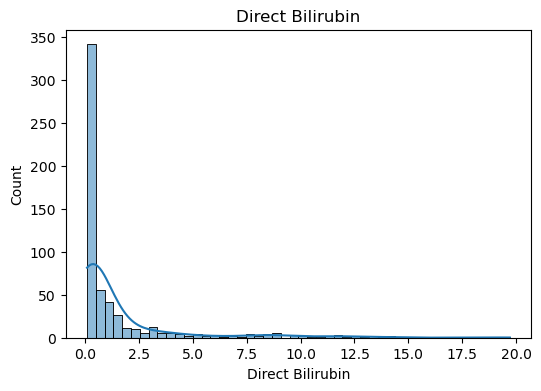

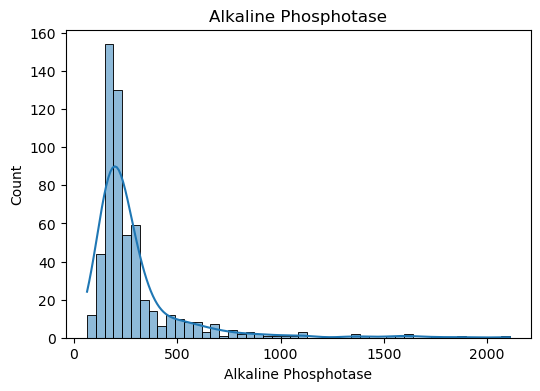

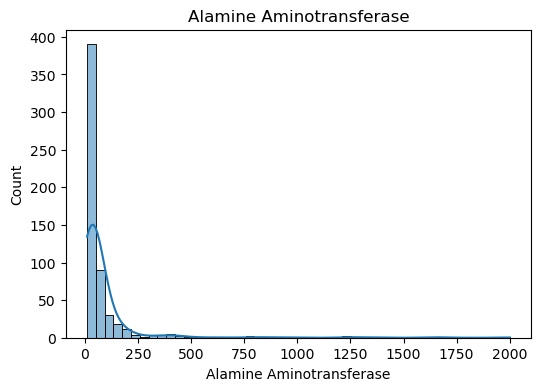

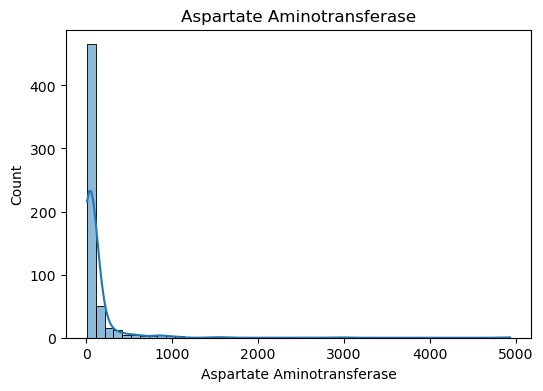

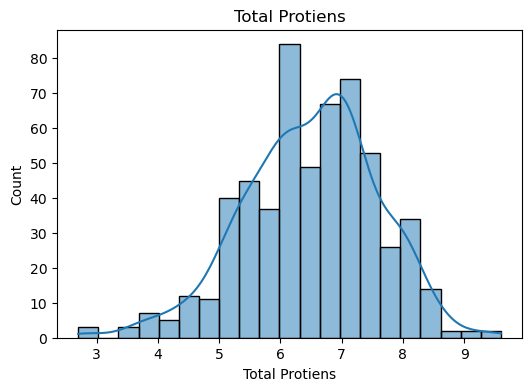

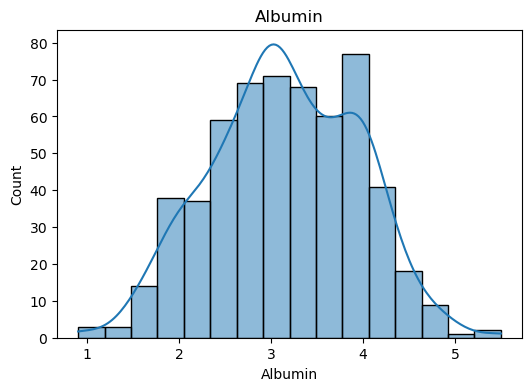

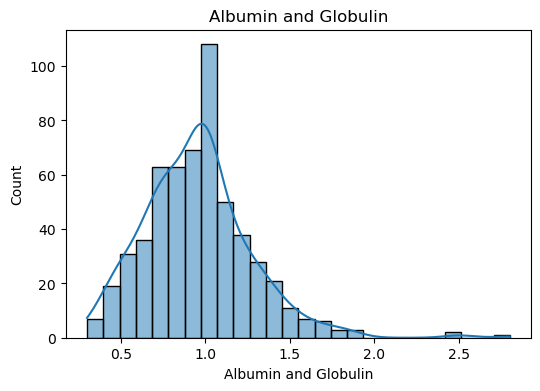

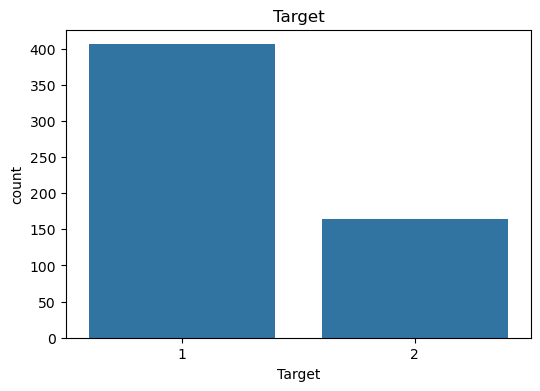

In [23]:
for column in data.columns:
    plt.figure(figsize=(6, 4))
    if column in ['Gender', 'Target']:
        sns.countplot(x=column, data=data)
    else:
        sns.histplot(x=column, data=data, kde=True)
    plt.title(column)
    plt.show()

### Observations:

#### -> We can observe proper normal distribution for the columns: Age, Total Protiens, Albumin, Albumin and Globulin

#### -> We can observe Right skewed distribution in the columns: Total Bilirubin, Direct Bilirubin, ALkaline Phospotase, Alamine Aminotransferase, Aspartate Aminotransferase

#### -> Based on age distribution we can say that liver disease is predicted on the basis of age too, where mostly patients aged from 40 to 60 are suffering fromn the Liver disease

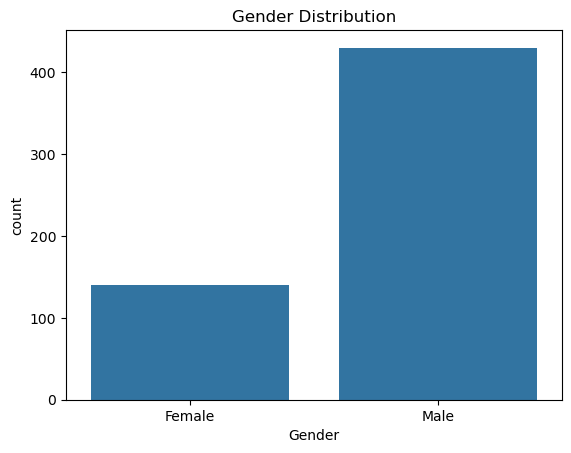

In [24]:
sns.countplot(x = data['Gender'])
plt.title("Gender Distribution")
plt.show()

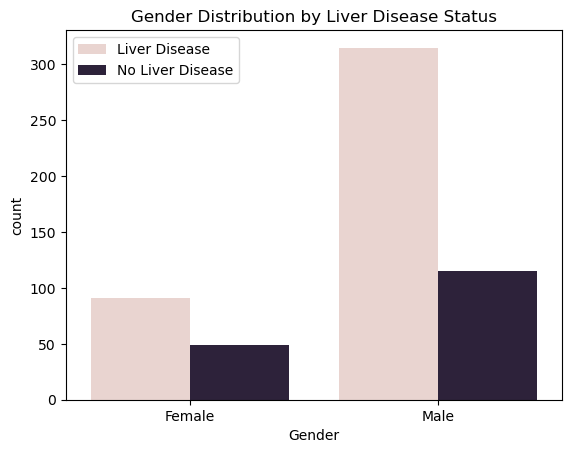

In [25]:
sns.countplot(x='Gender', hue='Target', data=data,
              order=['Female', 'Male'], hue_order=[1, 2])
plt.title("Gender Distribution by Liver Disease Status")
plt.legend(['Liver Disease', 'No Liver Disease'])
plt.show()

### Observations:

#### -> The above countplot shows that most of the patients are of male gender, that means data of gender is imbalanced

#### -> In the examination of liver disease prevalence across gender, higher propotion of male patients are diagnosed with liver disease, the difference is moderate than extreme. So we can say that gender plays a key role but not strongest predictor

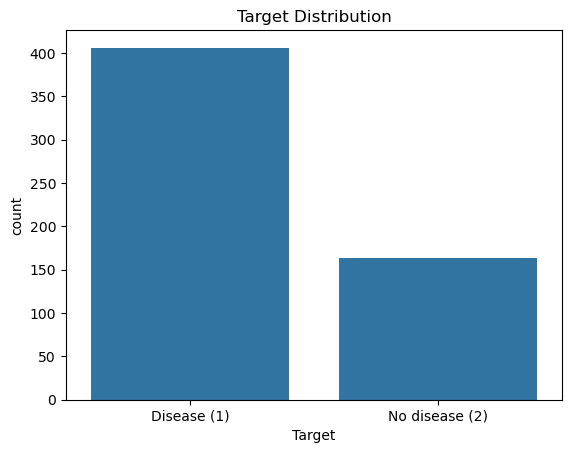

In [26]:
sns.countplot(x='Target', data=data)
plt.title("Target Distribution")
plt.xticks([0, 1], ['Disease (1)', 'No disease (2)'])
plt.show()

### Observtions:

#### -> Class imbalance: Live disease = 416, No disease = 167, so we use SMOTE to balance it

### Bivariate Analysis:

#### Checking the skewness of every numerical column of the data

In [27]:
num_cols = data.select_dtypes(include=np.number).columns.drop('Target')

In [28]:
skew_data = pd.DataFrame({
    'Feature': num_cols,
    'Skewness': [data[col].skew() for col in num_cols]
})

skew_data.sort_values(by='Skewness', ascending = False)

,Feature,Skewness
5,Aspartate Aminotransferase,10.559418
4,Alamine Aminotransferase,6.695054
1,Total Bilirubin,4.869459
3,Alkaline Phosphotase,3.728405
2,Direct Bilirubin,3.187685
8,Albumin and Globulin,1.001294
0,Age,-0.046597
7,Albumin,-0.060829
6,Total Protiens,-0.310929


### Observations:

#### we can observe around 5 features are highly right skewed

In [29]:
# Numerical vs Target

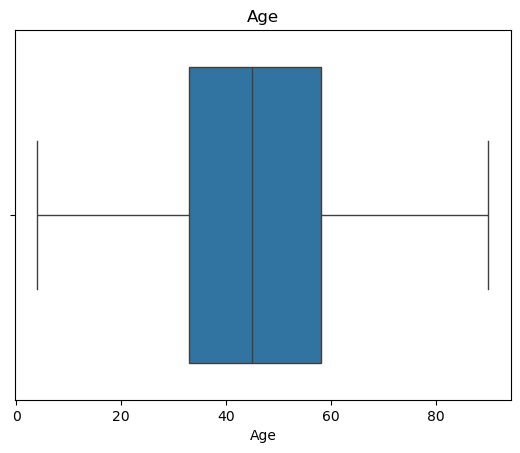

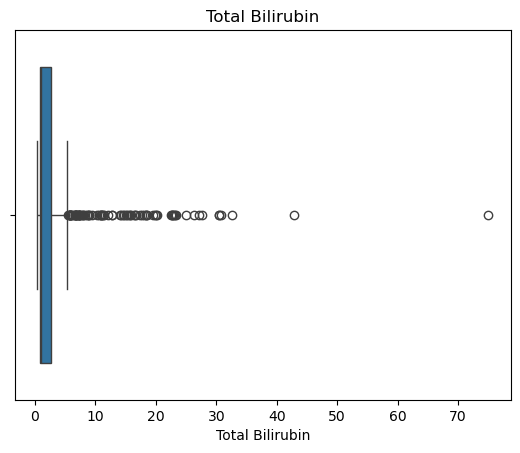

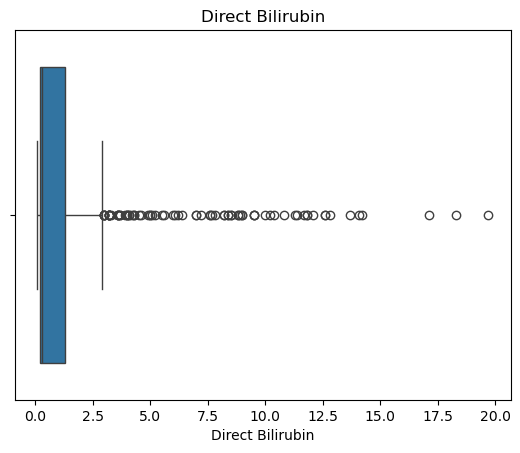

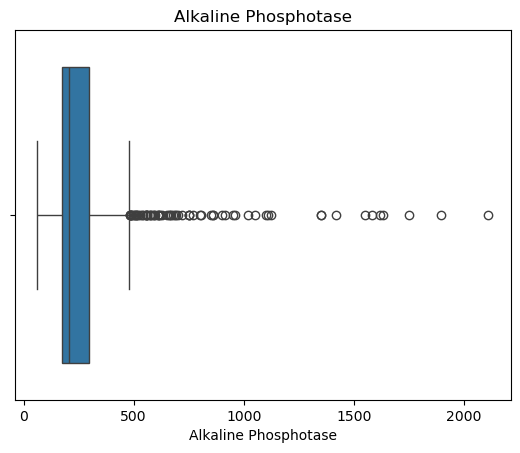

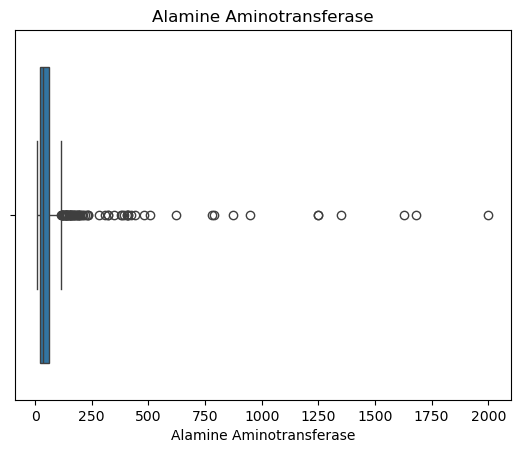

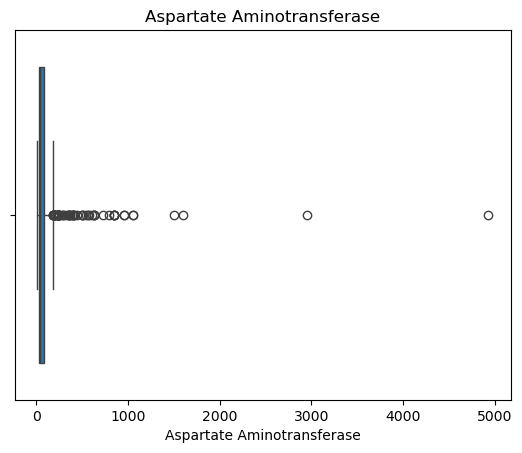

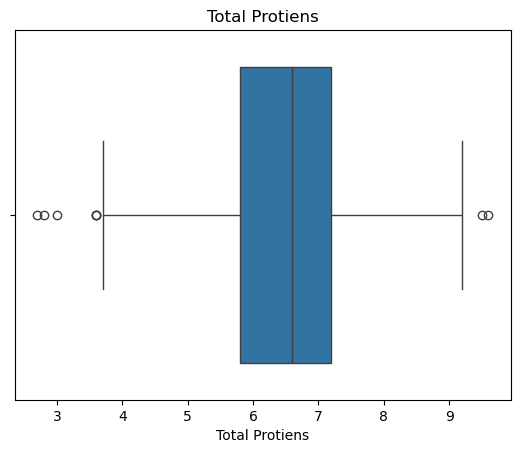

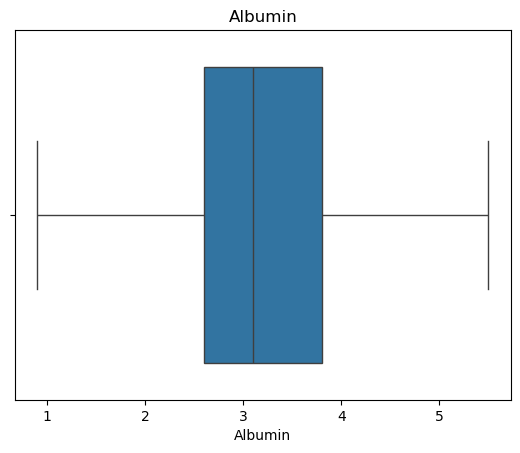

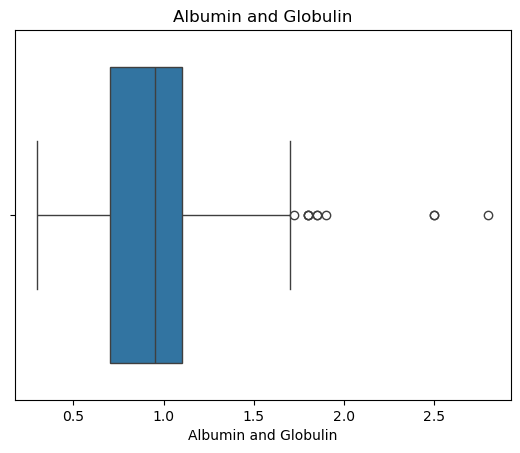

In [30]:
for col in num_cols:
    sns.boxplot(x=data[col])
    plt.title(col)
    plt.show()

In [31]:
# Categorical vs Target

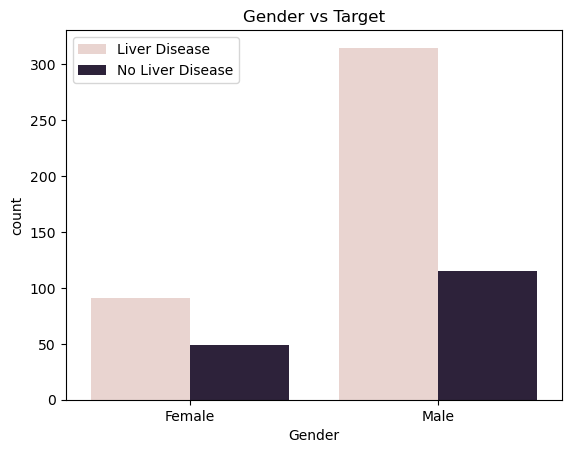

In [32]:
sns.countplot(x='Gender', hue='Target', data=data, hue_order=[1, 2])
plt.title("Gender vs Target")
plt.legend(['Liver Disease', 'No Liver Disease'])
plt.show()

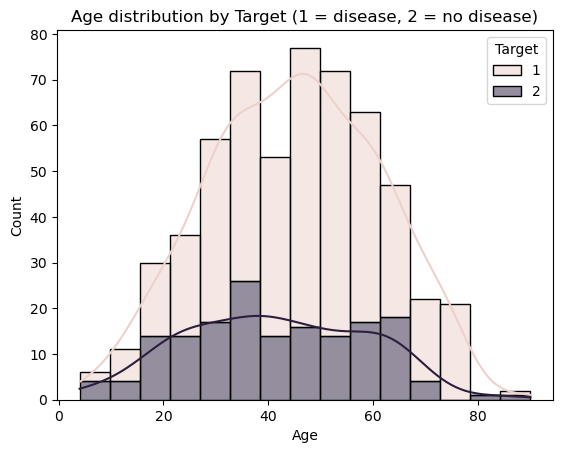

In [33]:
sns.histplot(data=data, x='Age', hue='Target', kde=True, multiple='stack')
plt.title("Age distribution by Target (1 = disease, 2 = no disease)")
plt.show()

In [34]:
age_band = pd.cut(data['Age'], [0, 20, 30, 40, 50, 60, 70, 100])
data.groupby(age_band, observed=True)['Target'].apply(lambda s: (s == 1).mean()).round(2)

Age
(0, 20]      0.55
(20, 30]     0.55
(30, 40]     0.75
(40, 50]     0.74
(50, 60]     0.79
(60, 70]     0.64
(70, 100]    0.90
Name: Target, dtype: float64

### Observations:

#### -> The above boxplots shows the behaviour of the features which are having outliers, 

In [35]:
# Numerical vs Numerical

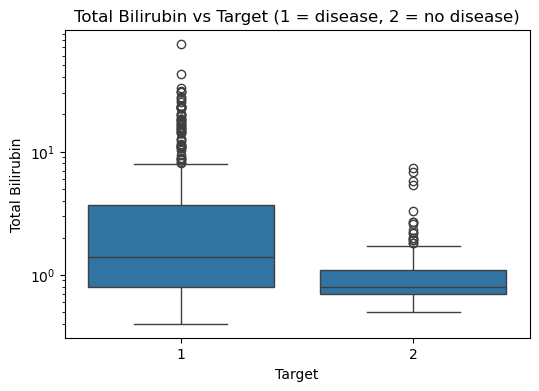

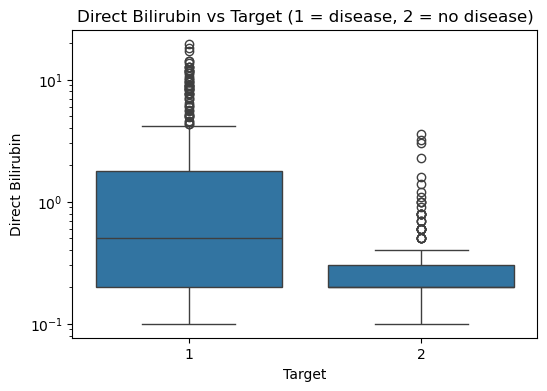

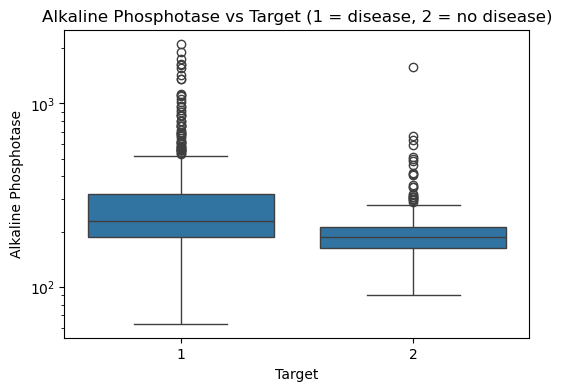

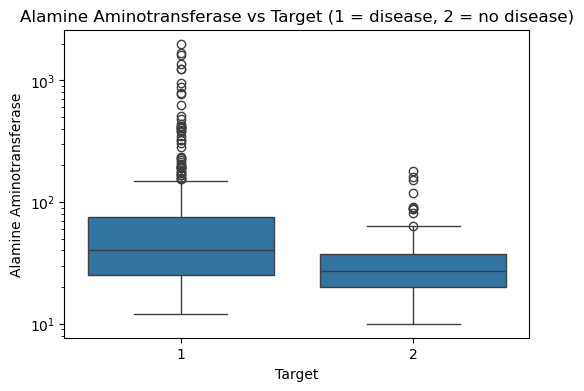

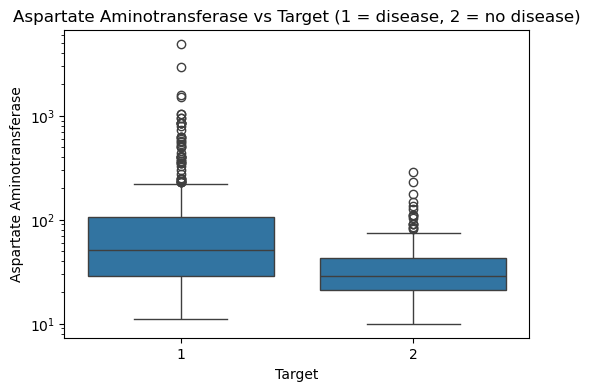

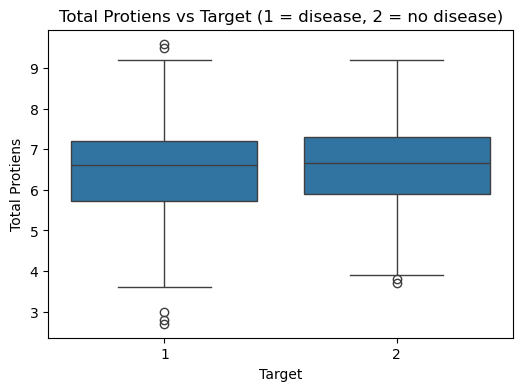

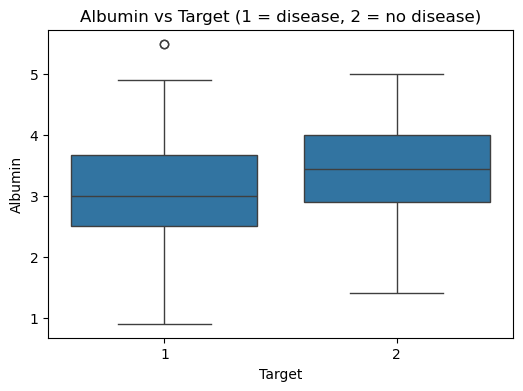

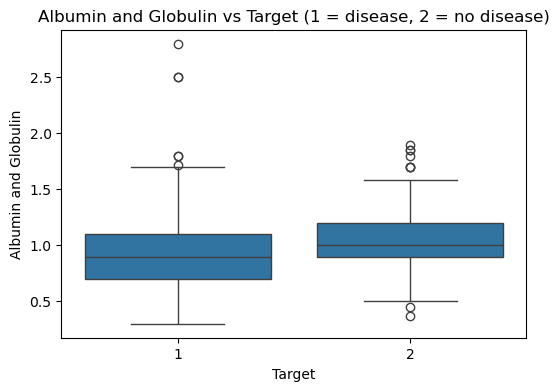

In [36]:
enzyme_cols = ['Total Bilirubin', 'Direct Bilirubin', 'Alkaline Phosphotase', 'Alamine Aminotransferase',
               'Aspartate Aminotransferase', 'Total Protiens', 'Albumin', 'Albumin and Globulin']

log_scale_cols = ['Total Bilirubin', 'Direct Bilirubin', 'Alkaline Phosphotase',
                  'Alamine Aminotransferase', 'Aspartate Aminotransferase']

for col in enzyme_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='Target', y=col, data=data)
    if col in log_scale_cols:
        plt.yscale('log')
    plt.title(f"{col} vs Target (1 = disease, 2 = no disease)")
    plt.show()

### Observations:

#### -> Patient with liver disease will have High Bilirubin levels, High enzyme levels (ALP, ALT, AST), Lower ALbumin levels

#### -> These features are highly predictive

#### Understanding the skewness of each numerical columns (enzymes), looks like these 6 features are right skewed where as the last one is not heavily skewed

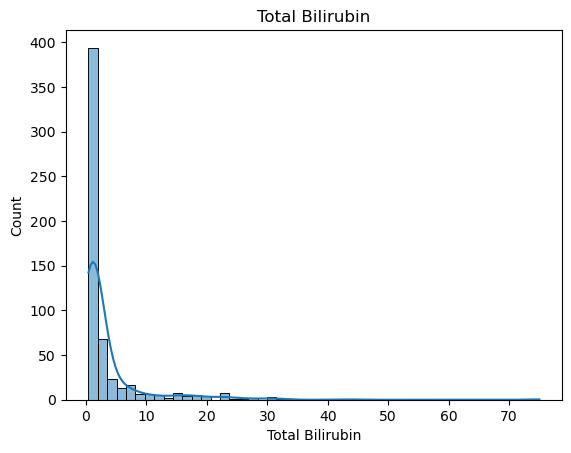

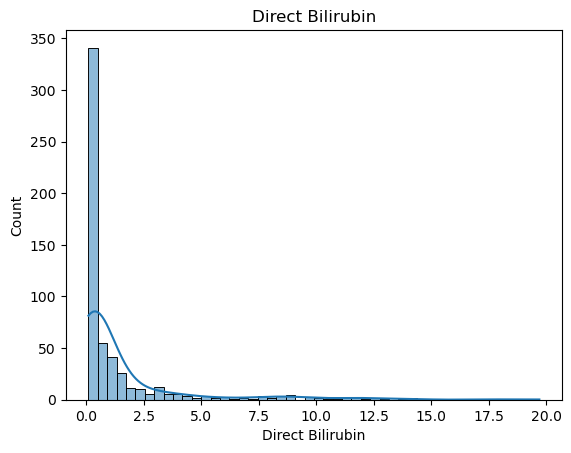

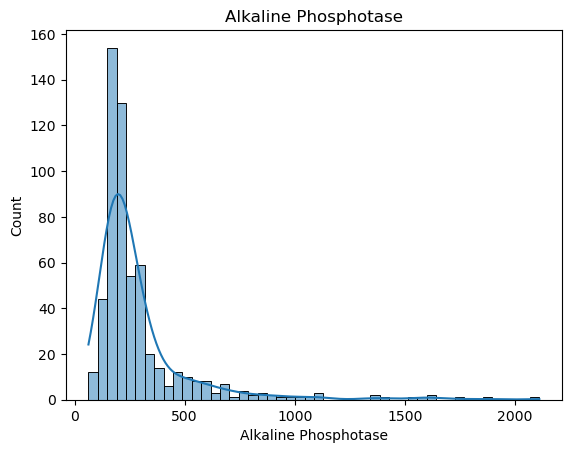

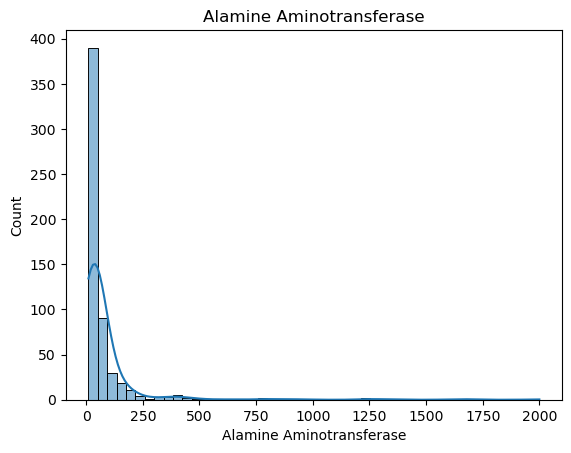

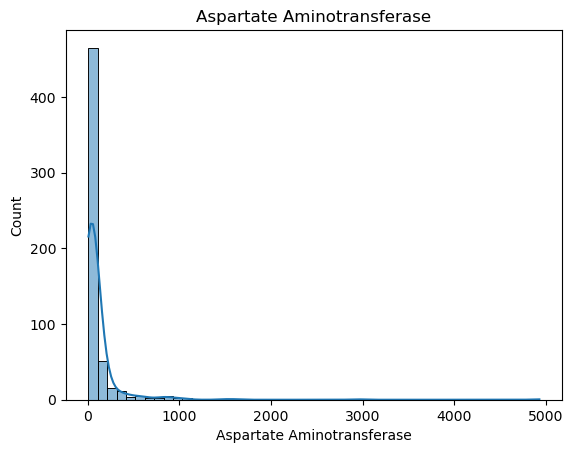

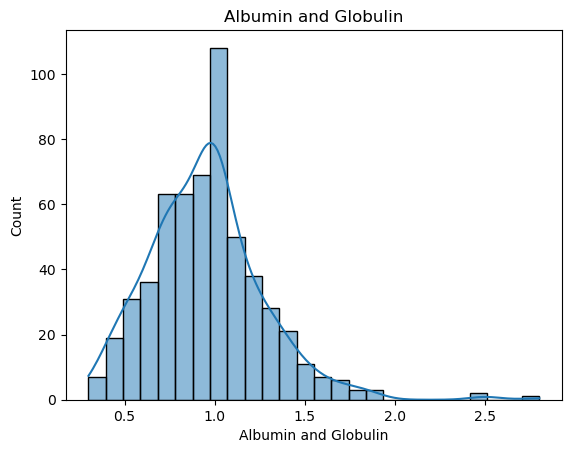

In [37]:
skewed_cols = data[enzyme_cols].skew()[abs(data[enzyme_cols].skew()) > 0.8].index

for col in skewed_cols:
    sns.histplot(data[col], kde = True)
    plt.title(col)
    plt.show()

### Multivariate:

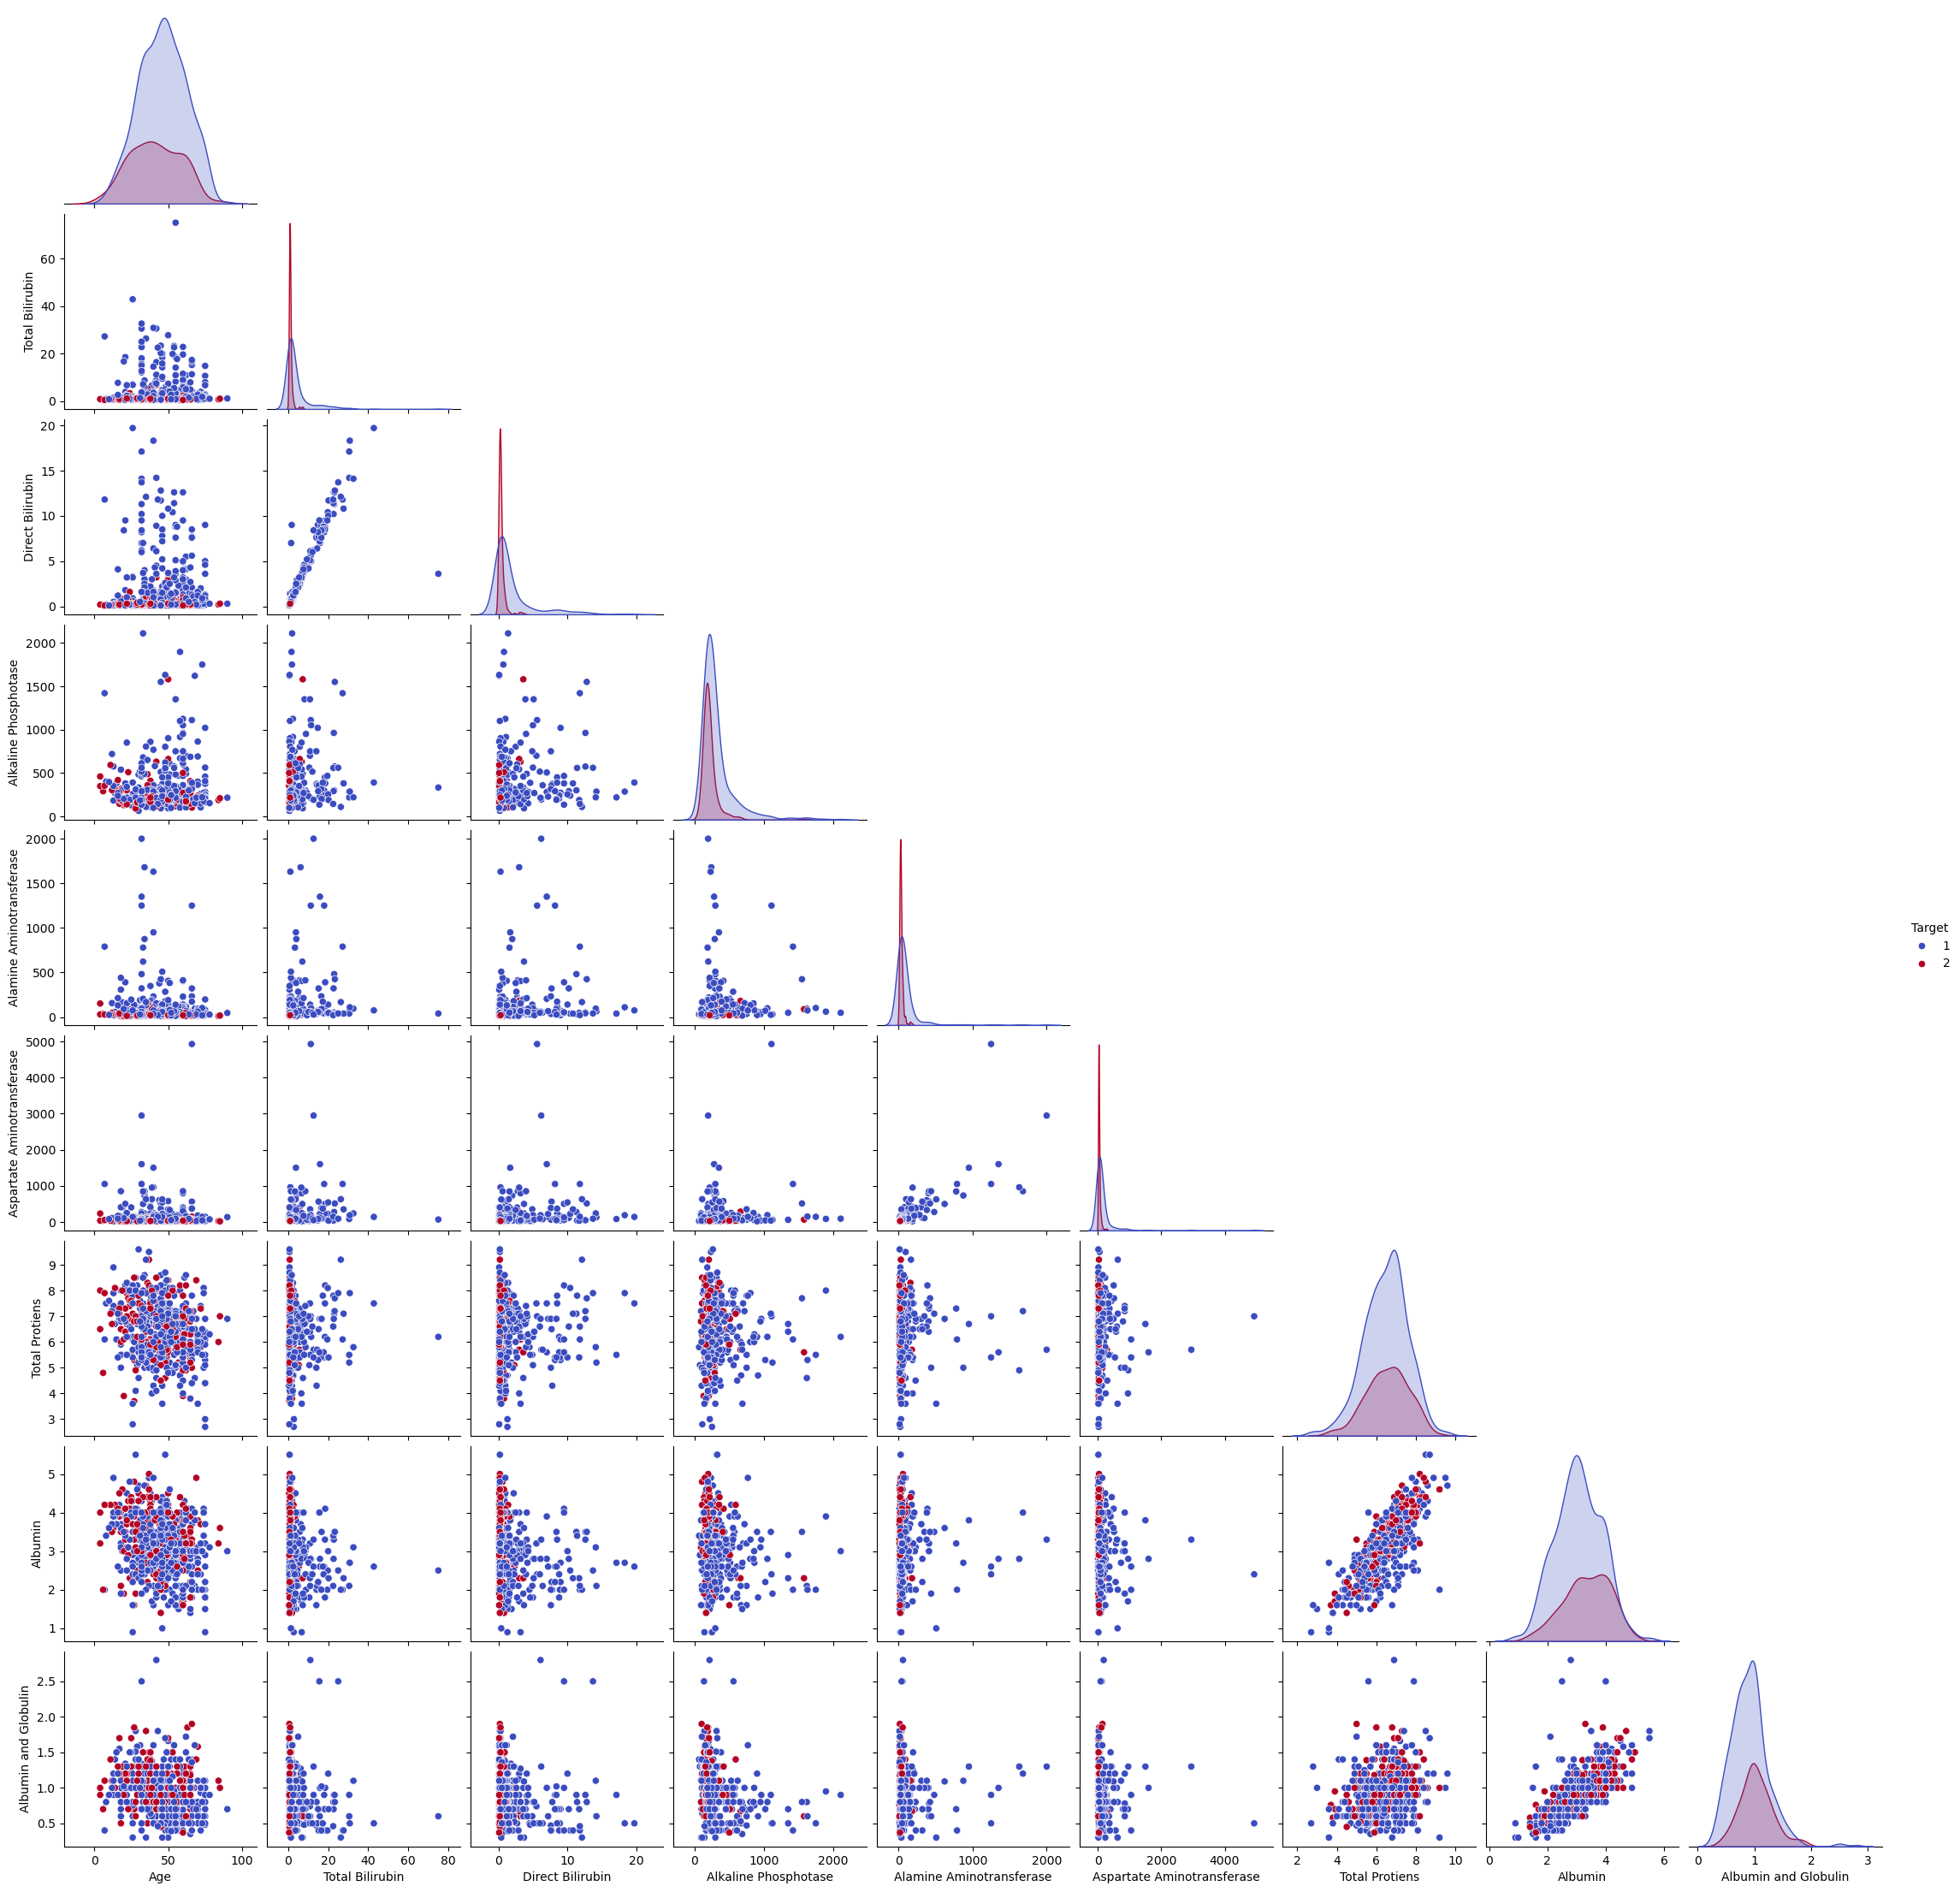

In [38]:
sns.pairplot(data, hue='Target', diag_kind='kde', palette='coolwarm', corner=True)
plt.show()

### Observations:

#### -> Clear clustering between disease and non disease in Bilirubin and Enzyme features

#### -> Some overlap exists and classification is not linearrly perfect

### Outliers:

#### Checking outlier for each column

In [39]:
def detect_outliers_iqr(df):
    outlier_summary = {}

    for col in df.select_dtypes(include=np.number).columns:
        if col in ['Target', 'Gender']:
            continue
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_summary[col] = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    return pd.DataFrame(list(outlier_summary.items()), columns=['Feature', 'Outlier_Count'])

In [40]:
outlier_report = detect_outliers_iqr(data)
outlier_report

,Feature,Outlier_Count
0,Age,0
1,Total Bilirubin,83
2,Direct Bilirubin,80
3,Alkaline Phosphotase,69
4,Alamine Aminotransferase,72
5,Aspartate Aminotransferase,66
6,Total Protiens,8
7,Albumin,0
8,Albumin and Globulin,10


### Observations:

#### -> Highest outliers: Total Bilirubin (83), Direct Bilirubin (80), Alamine Aminotransferase (72)

#### -> These are critical medical indicators

#### -> Instead of removing them we are log transforming them

### Data Preprocessing:

#### As we notiec 4 empty values in 'ALbumin and Globulin' column we fill that with Median

#### The reason we choose median over mean because this column is not normally distibuted, robust to outliers

In [41]:
data['Albumin and Globulin'].skew()

np.float64(1.0012944308926688)

In [42]:
print("Mean:", data['Albumin and Globulin'].mean())

Mean: 0.9480035335689044


In [43]:
print("Median:", data['Albumin and Globulin'].median())

Median: 0.95


In [44]:
data['Albumin and Globulin'] = data['Albumin and Globulin'].fillna(
    data['Albumin and Globulin'].median()
)

#### Instead of using Encoding technique we just replace Male and Female object values / text values to 1 and 0

In [45]:
data['Gender'] = data['Gender'].map({'Male':1, 'Female':0})
data

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin,Target
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,1,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
565,60,1,0.5,0.1,500,20,34,5.9,1.6,0.37,2
566,40,1,0.6,0.1,98,35,31,6.0,3.2,1.10,1
567,52,1,0.8,0.2,245,48,49,6.4,3.2,1.00,1
568,31,1,1.3,0.5,184,29,32,6.8,3.4,1.00,1


#### Parallely we change classification of person with disease and without disease from 1 and 2 to 0 and 1

In [46]:
data['Target'] = data['Target'].apply(lambda x: 1 if x == 1 else 0)
data

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin,Target
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,1,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
565,60,1,0.5,0.1,500,20,34,5.9,1.6,0.37,0
566,40,1,0.6,0.1,98,35,31,6.0,3.2,1.10,1
567,52,1,0.8,0.2,245,48,49,6.4,3.2,1.00,1
568,31,1,1.3,0.5,184,29,32,6.8,3.4,1.00,1


In [47]:
data

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin,Target
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,1,3.9,2.0,195,27,59,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
565,60,1,0.5,0.1,500,20,34,5.9,1.6,0.37,0
566,40,1,0.6,0.1,98,35,31,6.0,3.2,1.10,1
567,52,1,0.8,0.2,245,48,49,6.4,3.2,1.00,1
568,31,1,1.3,0.5,184,29,32,6.8,3.4,1.00,1


#### Checking the Correlation of all features of the dataset:

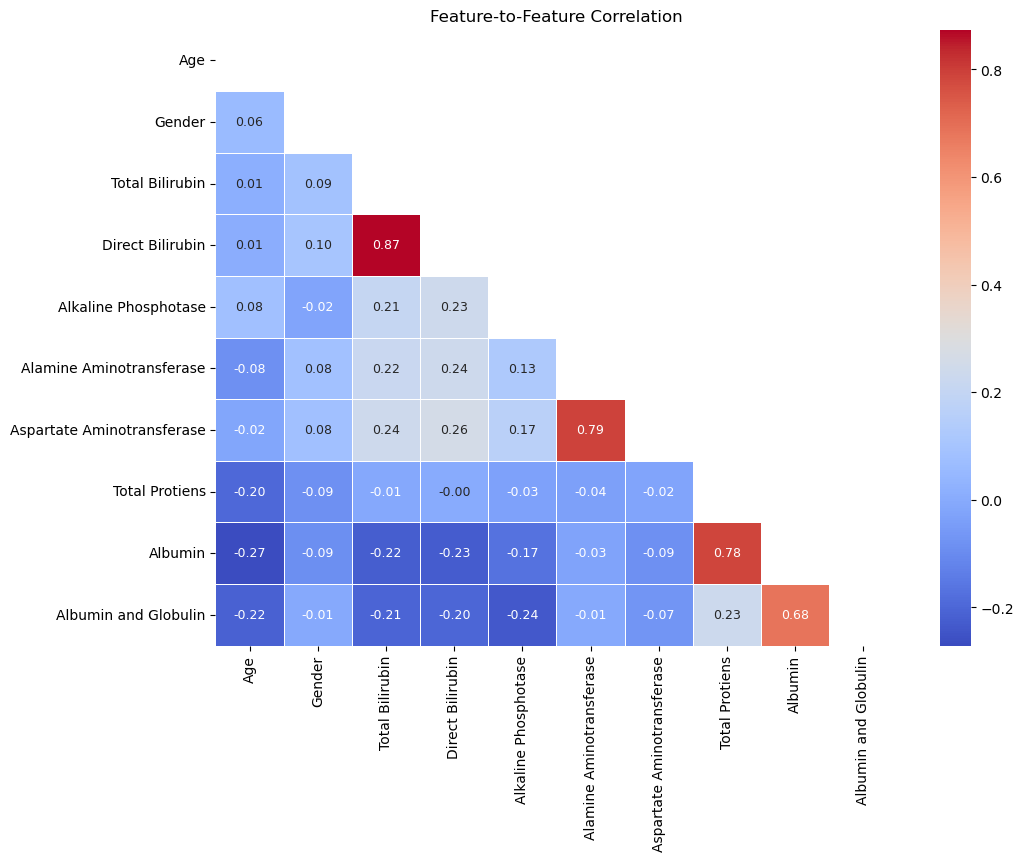

In [48]:
# Correlation:

feature_corr = data.drop(columns='Target').corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(feature_corr, dtype=bool))
sns.heatmap(feature_corr, mask=mask, annot=True, fmt=".2f", annot_kws={'size': 9},
            cmap="coolwarm", linewidths=0.5)
plt.title("Feature-to-Feature Correlation")
plt.show()

In [49]:
corr_matrix = data.drop(columns='Target').corr()

pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)
pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
pairs['Abs Corr'] = pairs['Correlation'].abs()
pairs = pairs.sort_values('Abs Corr', ascending=False).drop(columns='Abs Corr').reset_index(drop=True)

pairs.round(3)

,Feature 1,Feature 2,Correlation
0,Total Bilirubin,Direct Bilirubin,0.874
1,Alamine Aminotransferase,Aspartate Aminotransferase,0.792
2,Total Protiens,Albumin,0.785
3,Albumin,Albumin and Globulin,0.684
4,Age,Albumin,-0.271
5,Direct Bilirubin,Aspartate Aminotransferase,0.258
6,Total Bilirubin,Aspartate Aminotransferase,0.239
7,Direct Bilirubin,Alamine Aminotransferase,0.237
8,Alkaline Phosphotase,Albumin and Globulin,-0.236
9,Direct Bilirubin,Alkaline Phosphotase,0.235


### Observations:

#### -> we can see strong correlations between: Total Bilirubin - Direct Bilirubin = 0.87, ALT - AST = 0.79, Total Protiens - Albumin = 0.78

#### -> Target Correlation: Bilirubin and enzymes -> Positive correlation, Albumin -> Negative correlation

#### High enzymes -> Disease, Low albumin -> Disease

In [50]:
# Log transformation

#### As we noticed some features as right skewed so we apply Log Transformation

In [51]:
skewed_features = [
    'Total Bilirubin',
    'Direct Bilirubin',
    'Alamine Aminotransferase',
    'Aspartate Aminotransferase',
    'Alkaline Phosphotase'
]

for col in skewed_features:
    data[col] = np.log1p(data[col])

In [52]:
data

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin,Target
0,65,0,0.530628,0.095310,5.236442,2.833213,2.944439,6.8,3.3,0.90,1
1,62,1,2.476538,1.871802,6.551080,4.174387,4.615121,7.5,3.2,0.74,1
2,62,1,2.116256,1.629241,6.196444,4.110874,4.234107,7.0,3.3,0.89,1
3,58,1,0.693147,0.336472,5.209486,2.708050,3.044522,6.8,3.4,1.00,1
4,72,1,1.589235,1.098612,5.278115,3.332205,4.094345,7.3,2.4,0.40,1
...,...,...,...,...,...,...,...,...,...,...,...
565,60,1,0.405465,0.095310,6.216606,3.044522,3.555348,5.9,1.6,0.37,0
566,40,1,0.470004,0.095310,4.595120,3.583519,3.465736,6.0,3.2,1.10,1
567,52,1,0.587787,0.182322,5.505332,3.891820,3.912023,6.4,3.2,1.00,1
568,31,1,0.832909,0.405465,5.220356,3.401197,3.496508,6.8,3.4,1.00,1


Total Bilirubin               1.73
Direct Bilirubin              1.69
Alamine Aminotransferase      1.47
Aspartate Aminotransferase    1.25
Alkaline Phosphotase          1.33
dtype: float64


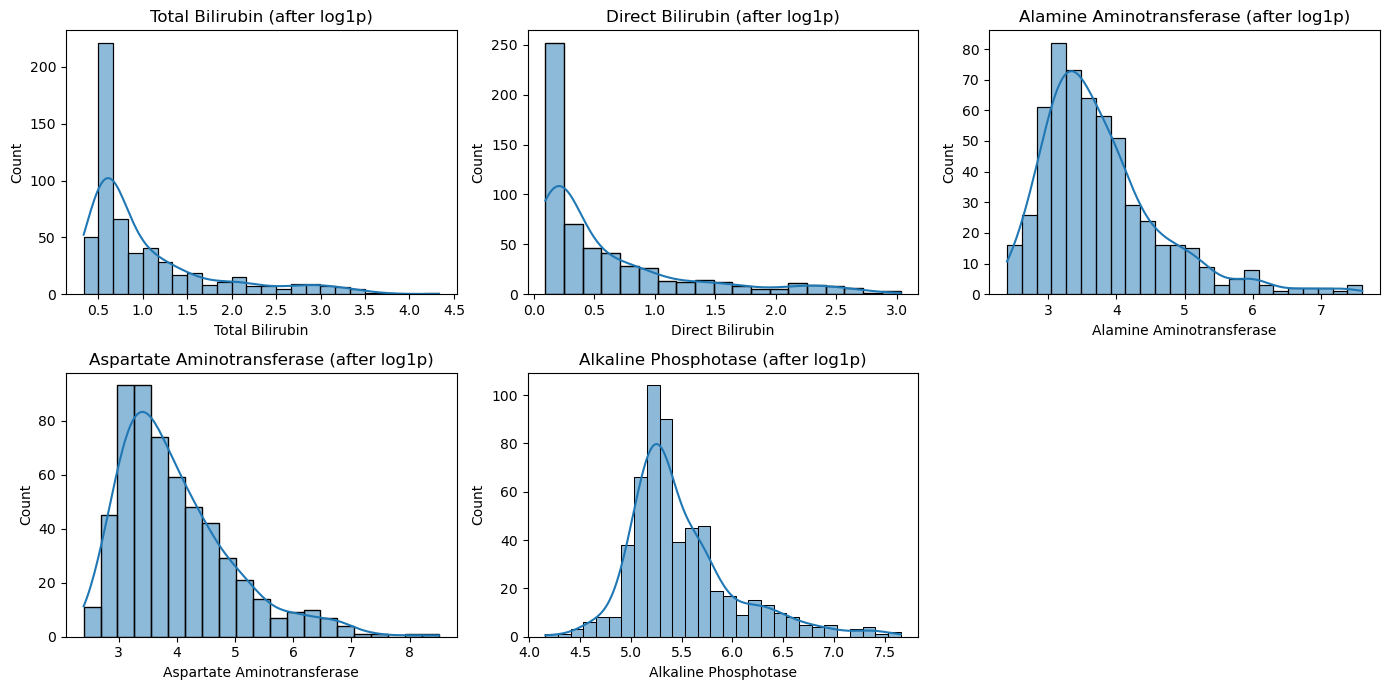

In [53]:
print(data[skewed_features].skew().round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()
for ax, col in zip(axes, skewed_features):
    sns.histplot(data[col], kde=True, ax=ax)
    ax.set_title(f"{col} (after log1p)")
axes[-1].axis('off')
plt.tight_layout()
plt.show()

In [54]:
corr_matrix = data.drop(columns='Target').corr()

pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)
pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
pairs['Abs Corr'] = pairs['Correlation'].abs()
pairs = pairs.sort_values('Abs Corr', ascending=False).drop(columns='Abs Corr').reset_index(drop=True)
pairs.head(6).round(3)

,Feature 1,Feature 2,Correlation
0,Total Bilirubin,Direct Bilirubin,0.975
1,Alamine Aminotransferase,Aspartate Aminotransferase,0.841
2,Total Protiens,Albumin,0.785
3,Albumin,Albumin and Globulin,0.684
4,Total Bilirubin,Aspartate Aminotransferase,0.535
5,Direct Bilirubin,Aspartate Aminotransferase,0.529


In [55]:
x = data.drop('Target', axis = 1)
y = data['Target']

In [56]:
x

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin
0,65,0,0.530628,0.095310,5.236442,2.833213,2.944439,6.8,3.3,0.90
1,62,1,2.476538,1.871802,6.551080,4.174387,4.615121,7.5,3.2,0.74
2,62,1,2.116256,1.629241,6.196444,4.110874,4.234107,7.0,3.3,0.89
3,58,1,0.693147,0.336472,5.209486,2.708050,3.044522,6.8,3.4,1.00
4,72,1,1.589235,1.098612,5.278115,3.332205,4.094345,7.3,2.4,0.40
...,...,...,...,...,...,...,...,...,...,...
565,60,1,0.405465,0.095310,6.216606,3.044522,3.555348,5.9,1.6,0.37
566,40,1,0.470004,0.095310,4.595120,3.583519,3.465736,6.0,3.2,1.10
567,52,1,0.587787,0.182322,5.505332,3.891820,3.912023,6.4,3.2,1.00
568,31,1,0.832909,0.405465,5.220356,3.401197,3.496508,6.8,3.4,1.00


In [57]:
x.shape

(570, 10)

In [58]:
y.shape

(570,)

# TASK 2: Create a predictive model with implementation of different classifiers on liver patient diseases dataset to predict liver diseases:

### Modelling:

#### The data is split into training and testing for about 80% and 20%

In [59]:
# Train test split:
# from sklearn.model_selection import train_test_split
# x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state = 42, stratify = y)


from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC
from sklearn.preprocessing import StandardScaler

x = data.drop('Target', axis=1)
y = data['Target']

# 1. Split first (stratified keeps the class ratio equal in both sets)
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape: ", x_train.shape)
print("Testing set shape:", x_test.shape)
print("\nTrain class distribution:\n", y_train.value_counts())
print("\nTest class distribution:\n", y_test.value_counts())

Training set shape:  (456, 10)
Testing set shape: (114, 10)

Train class distribution:
 Target
1    325
0    131
Name: count, dtype: int64

Test class distribution:
 Target
1    81
0    33
Name: count, dtype: int64


In [60]:
print("\n Training target distribution:")
print(y_train.value_counts(normalize = True))
print("\n Testing target distribution:")
print(y_test.value_counts(normalize = False))


 Training target distribution:
Target
1    0.712719
0    0.287281
Name: proportion, dtype: float64

 Testing target distribution:
Target
1    81
0    33
Name: count, dtype: int64


In [61]:
x_train

,Age,Gender,Total Bilirubin,Direct Bilirubin,Alkaline Phosphotase,Alamine Aminotransferase,Aspartate Aminotransferase,Total Protiens,Albumin,Albumin and Globulin
216,46,1,0.470004,0.182322,5.673323,3.295837,3.091042,6.0,3.0,1.00
107,50,1,1.916923,1.386294,6.495266,5.204007,5.655992,5.7,2.3,0.67
47,45,0,0.530628,0.182322,5.141664,3.091042,2.708050,5.7,2.5,0.70
300,30,0,0.587787,0.182322,5.068904,3.258097,3.135494,7.9,4.5,1.30
160,44,0,1.064711,0.470004,5.700444,5.937536,6.401917,6.6,3.3,1.00
...,...,...,...,...,...,...,...,...,...,...
403,70,1,0.470004,0.095310,6.760415,4.343805,5.198497,6.3,2.7,0.75
455,66,1,0.693147,0.262364,5.252273,3.433987,4.007333,5.3,2.1,0.60
456,66,1,0.587787,0.182322,5.111988,3.135494,3.496508,4.4,2.0,0.80
196,45,0,0.641854,0.262364,5.247024,3.178054,3.526361,6.6,3.9,0.95


#### Models like Logistic Regression and SVM are sensitive to fearture magnitude so we apply Standard Scalar

In [62]:
# Standard Scaling:

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

#### Now handling the imbalanced data , to prevent model being biased towards the majority class we are applying SMOTE

In [63]:
# Handling imbalanced data

smote = SMOTENC(categorical_features=[1], random_state=42)
x_train_sm, y_train_sm = smote.fit_resample(x_train_scaled, y_train)

print("Before SMOTE:\n", y_train.value_counts())
print("\nAfter SMOTE:\n", y_train_sm.value_counts())

# Name used by the model cells that follow
x_train_sm_scaled = x_train_sm

Before SMOTE:
 Target
1    325
0    131
Name: count, dtype: int64

After SMOTE:
 Target
1    325
0    325
Name: count, dtype: int64


### Feature Engineering and Transformation
- Duplicates (13) were removed so the same patient cannot appear in both train and test sets.
- The 4 missing Albumin/Globulin values were filled with the median (0.95), which is robust to skew and outliers.
- Gender was binary-encoded (Male = 1, Female = 0) and Target recoded so that 1 = liver disease, 0 = no disease.
- log1p was applied to the five skewed features. It reduced skewness from 3.2-10.6 to 1.25-1.73: much closer to
  symmetric but still moderately skewed. No further transformation was applied, since the extreme values are meaningful.
- A stratified 80/20 split (456 train / 114 test) preserved the class ratio. StandardScaler was fitted on the training
  data only, then SMOTENC (Gender treated as categorical) was applied to the training set only, so the test set stayed
  untouched and no information leaked.

# TASK3: Create an analysis to show on what basis you have designed your model:

In [64]:
# Modelling:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'SVM': SVC(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                             eval_metric='logloss', random_state=42)
}

results = []
conf_matrices = {}

for name, model in models.items():
    model.fit(x_train_sm_scaled, y_train_sm)
    y_pred = model.predict(x_test_scaled)

    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(x_test_scaled)[:, 1]
    else:
        y_score = model.decision_function(x_test_scaled)    # SVM without probability

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_score)
    })
    conf_matrices[name] = confusion_matrix(y_test, y_pred)

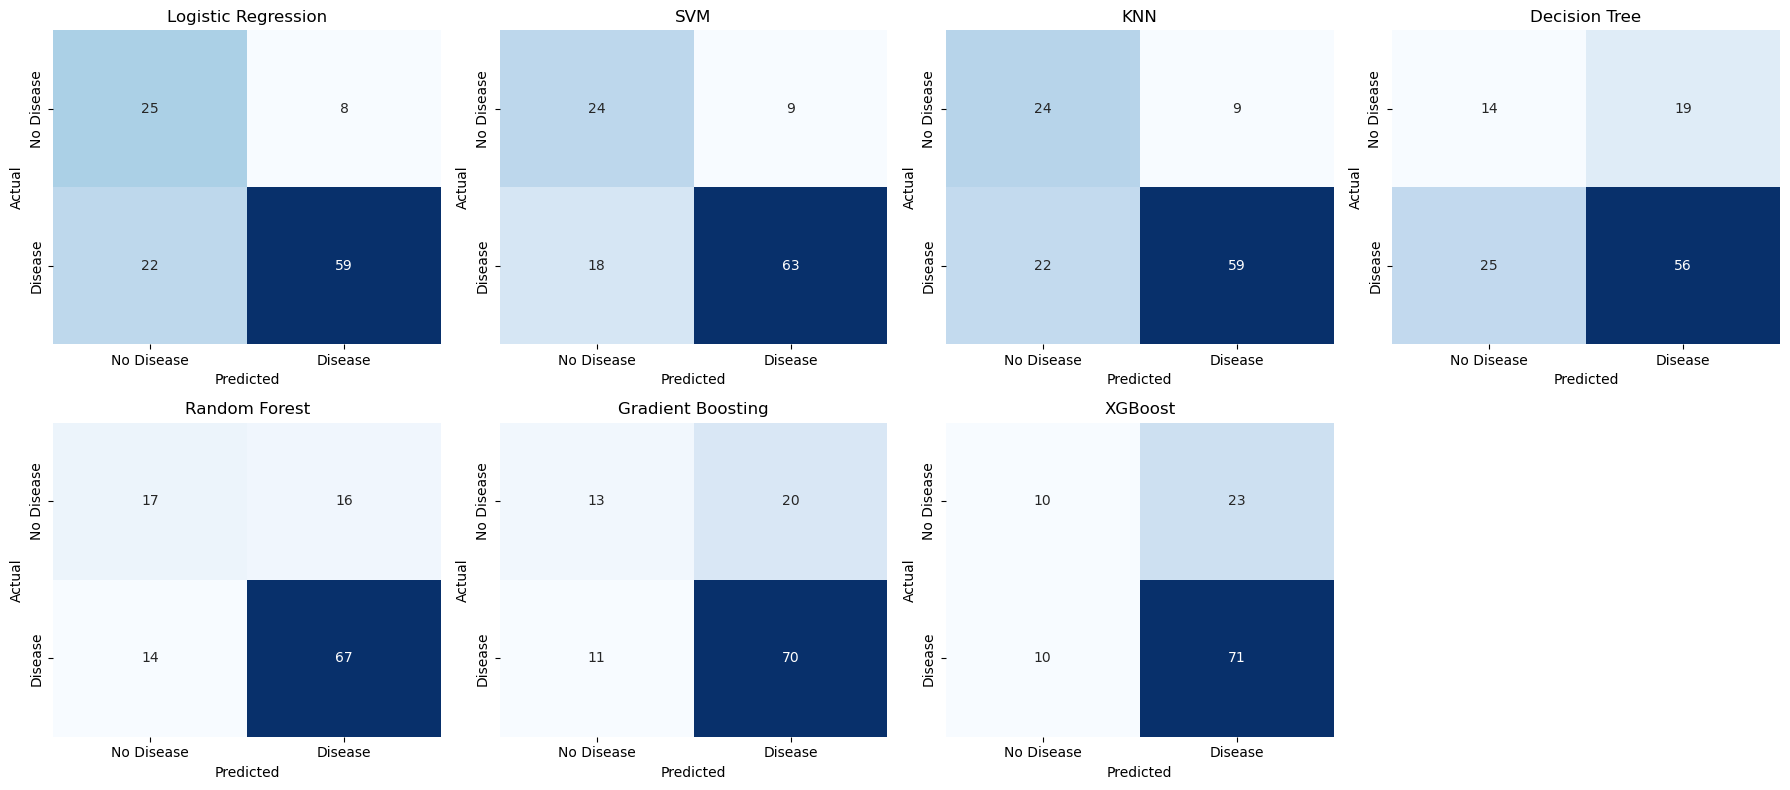

In [65]:
# evaluation:

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for ax, (name, cm) in zip(axes, conf_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No Disease', 'Disease'],
                yticklabels=['No Disease', 'Disease'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

axes[-1].axis('off')      # 7 models, 8 slots
plt.tight_layout()
plt.show()

In [66]:
results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.737,0.881,0.728,0.797,0.828
1,SVM,0.763,0.875,0.778,0.824,0.793
2,KNN,0.728,0.868,0.728,0.792,0.787
3,Gradient Boosting,0.728,0.778,0.864,0.819,0.785
4,Random Forest,0.737,0.807,0.827,0.817,0.777
5,XGBoost,0.711,0.755,0.877,0.811,0.765
6,Decision Tree,0.614,0.747,0.691,0.718,0.558


### Baseline model evaluation (before tuning)
- Ranked by ROC-AUC: Logistic Regression 0.828, SVM 0.793, KNN 0.787, Gradient Boosting 0.785, Random Forest 0.777,
  XGBoost 0.765, Decision Tree 0.558.
- Boosting and bagging models had the highest recall (0.83-0.88) but only by flagging many healthy patients: XGBoost
  missed 10 diseased patients and raised 23 false alarms; Gradient Boosting 11 and 20.
- Logistic Regression, SVM and KNN were more conservative: 8-9 false alarms but 18-22 missed patients.
- The unconstrained Decision Tree overfitted (AUC 0.558, close to random).
- Accuracy (0.61-0.76) is close to the 0.711 obtained by predicting "disease" for everyone, so precision, recall and
  ROC-AUC are more informative.

In [67]:
# Hyperparameter tuning:

# Hyperparameter tuning (SMOTE inside each CV fold):

from imblearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tuning = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42),
                            {'C': [0.001, 0.01, 0.1, 1, 10]}),
    'SVM': (SVC(probability=True, random_state=42),
            {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.01, 0.1, 1]}),
    'KNN': (KNeighborsClassifier(),
            {'n_neighbors': [5, 9, 15, 21, 31], 'weights': ['uniform', 'distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42),
                      {'max_depth': [2, 3, 4, 5, 7], 'min_samples_leaf': [5, 10, 20, 30]}),
    'Random Forest': (RandomForestClassifier(random_state=42),
                      {'n_estimators': [200, 400], 'max_depth': [3, 4, 6, 8, None],
                       'min_samples_leaf': [1, 3, 5, 10]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=42),
                          {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.05, 0.1],
                           'max_depth': [2, 3, 4], 'subsample': [0.7, 1.0]}),
    'XGBoost': (XGBClassifier(eval_metric='logloss', random_state=42),
                {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.05, 0.1],
                 'max_depth': [2, 3, 4], 'subsample': [0.7, 1.0]})
}

tuned_results = []
tuned_conf = {}
tuned_models = {}

for name, (model, params) in tuning.items():
    pipe = Pipeline([('smote', SMOTENC(categorical_features=[1], random_state=42)),
                     ('clf', model)])
    grid = GridSearchCV(pipe, {f'clf__{k}': v for k, v in params.items()},
                        cv=cv, scoring='roc_auc', n_jobs=-1)
    grid.fit(x_train_scaled, y_train)        # real training rows; SMOTE runs inside each fold

    best = grid.best_estimator_.named_steps['clf']   # classifier refitted on the SMOTE'd training set
    y_pred = best.predict(x_test_scaled)
    y_prob = best.predict_proba(x_test_scaled)[:, 1]

    tuned_models[name] = best
    tuned_conf[name] = confusion_matrix(y_test, y_pred)
    tuned_results.append({
        'Model': name,
        'Best Params': grid.best_params_,
        'CV ROC-AUC': grid.best_score_,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })
    print(f"{name}: {grid.best_params_} | CV AUC {grid.best_score_:.3f}")

Logistic Regression: {'clf__C': 0.001} | CV AUC 0.723


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM: {'clf__C': 1, 'clf__gamma': 0.01} | CV AUC 0.719
KNN: {'clf__n_neighbors': 31, 'clf__weights': 'distance'} | CV AUC 0.679
Decision Tree: {'clf__max_depth': 3, 'clf__min_samples_leaf': 30} | CV AUC 0.699
Random Forest: {'clf__max_depth': 6, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 400} | CV AUC 0.717
Gradient Boosting: {'clf__learning_rate': 0.01, 'clf__max_depth': 4, 'clf__n_estimators': 200, 'clf__subsample': 0.7} | CV AUC 0.697
XGBoost: {'clf__learning_rate': 0.01, 'clf__max_depth': 4, 'clf__n_estimators': 50, 'clf__subsample': 0.7} | CV AUC 0.698


In [68]:
# Comparison table
tuned_df = pd.DataFrame(tuned_results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
tuned_df.drop(columns='Best Params').round(3)

,Model,CV ROC-AUC,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,SVM,0.719,0.711,0.929,0.642,0.759,0.840
1,Logistic Regression,0.723,0.719,0.915,0.667,0.771,0.828
2,KNN,0.679,0.746,0.906,0.716,0.800,0.827
3,Random Forest,0.717,0.737,0.849,0.765,0.805,0.812
4,Gradient Boosting,0.697,0.719,0.845,0.741,0.789,0.789
5,XGBoost,0.698,0.746,0.851,0.778,0.813,0.785
6,Decision Tree,0.699,0.702,0.851,0.704,0.770,0.757


### Hyperparameter tuning
- All seven models were tuned with GridSearchCV (5-fold shuffled stratified CV, scoring ROC-AUC). SMOTENC was placed
  inside a pipeline so synthetic samples are created only from the training part of each fold.
- Best parameters: Logistic Regression C = 0.001; SVM C = 1, gamma = 0.01; KNN k = 31 (distance weights); Decision
  Tree depth 3, min leaf 30; Random Forest depth 6, min leaf 10, 400 trees; Gradient Boosting learning rate 0.01,
  depth 4, 200 trees, subsample 0.7; XGBoost learning rate 0.01, depth 4, 50 trees, subsample 0.7.
- Every model preferred simple, heavily regularised settings: with a small, noisy dataset and overlapping classes,
  added complexity fits noise rather than signal.
- Cross-validated ROC-AUC: Logistic Regression 0.723, SVM 0.719, Random Forest 0.717, Decision Tree 0.699,
  XGBoost 0.698, Gradient Boosting 0.697, KNN 0.679.
- An earlier version applied SMOTE before cross-validation and reported CV AUC up to 0.89; that was inflated, because
  validation folds contained synthetic samples built from training rows.

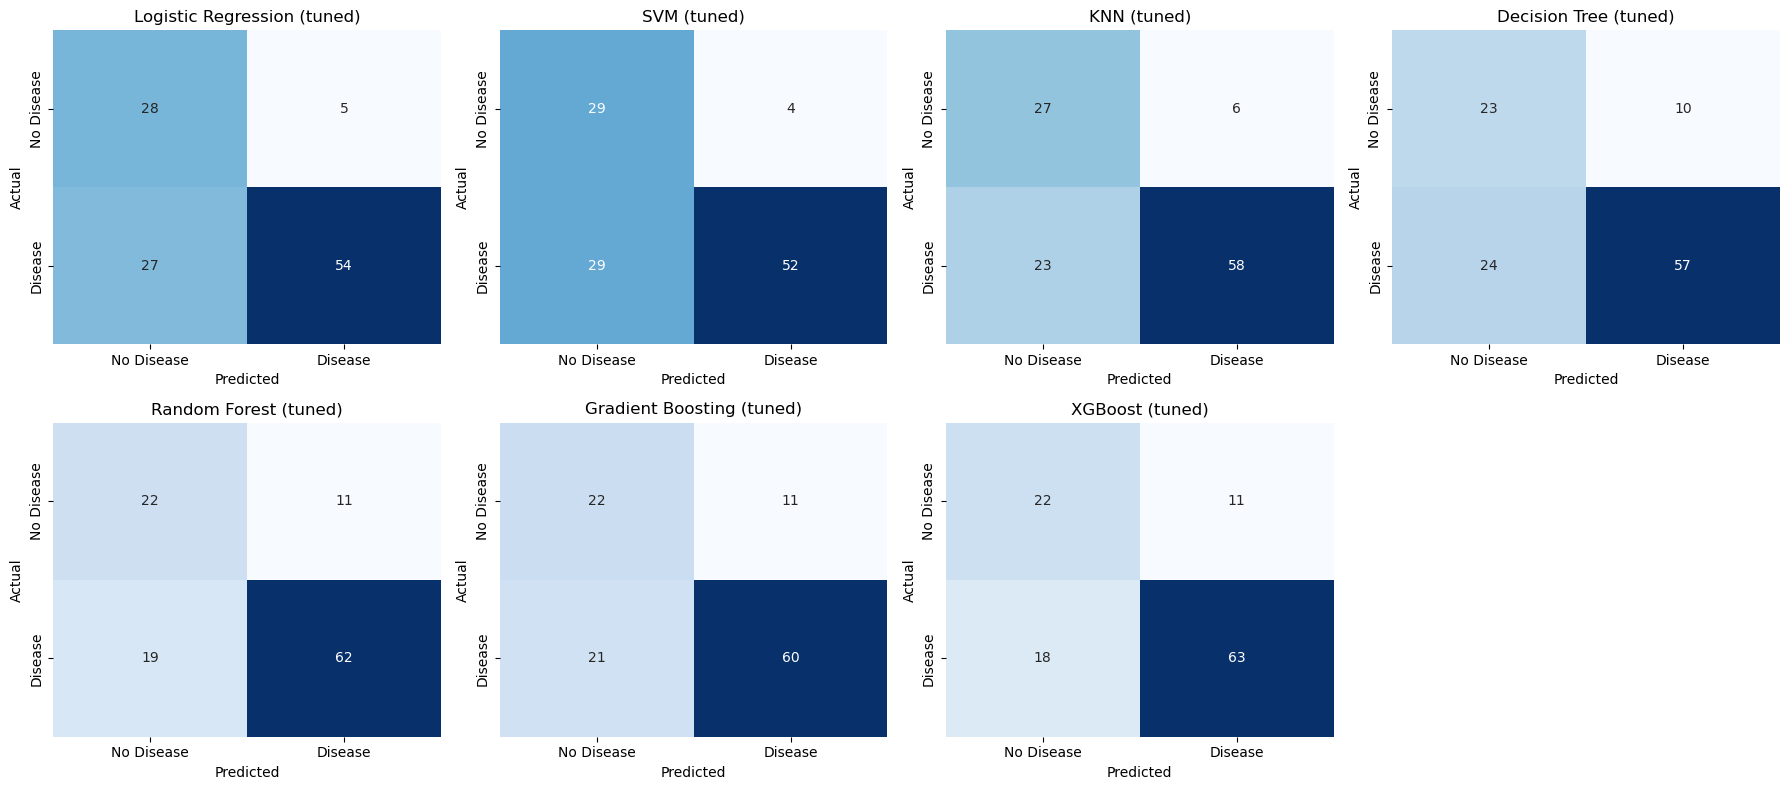

In [69]:
# Confusion matrices
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for ax, (name, cm) in zip(axes, tuned_conf.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No Disease', 'Disease'],
                yticklabels=['No Disease', 'Disease'])
    ax.set_title(f"{name} (tuned)")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

axes[-1].axis('off')
plt.tight_layout()
plt.show()

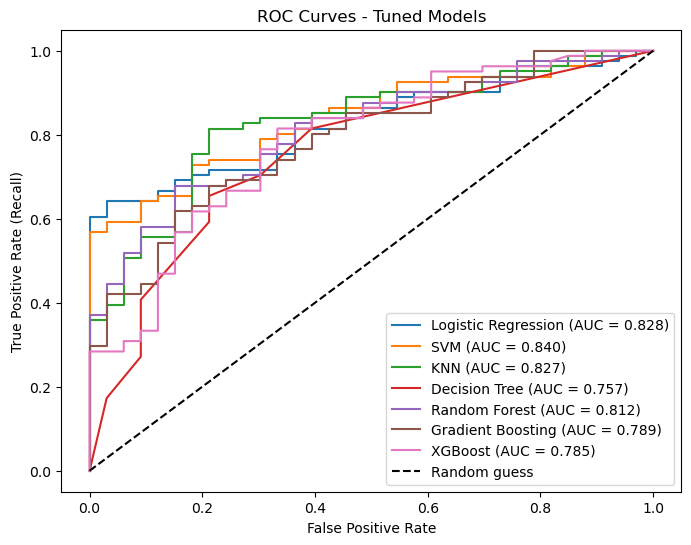

In [70]:
# ROC AUC curve:

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for name, model in tuned_models.items():
    y_prob = model.predict_proba(x_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves - Tuned Models")
plt.legend(loc='lower right')
plt.show()

### Tuned model evaluation and ROC-AUC (default threshold 0.5)
| Model | Accuracy | Precision | Recall | ROC-AUC | Missed | False alarms |
|---|---|---|---|---|---|---|
| SVM | 0.711 | 0.929 | 0.642 | 0.840 | 29 | 4 |
| Logistic Regression | 0.719 | 0.915 | 0.667 | 0.828 | 27 | 5 |
| KNN | 0.746 | 0.906 | 0.716 | 0.827 | 23 | 6 |
| Random Forest | 0.737 | 0.849 | 0.765 | 0.812 | 19 | 11 |
| Gradient Boosting | 0.719 | 0.845 | 0.741 | 0.789 | 21 | 11 |
| XGBoost | 0.746 | 0.851 | 0.778 | 0.785 | 18 | 11 |
| Decision Tree | 0.702 | 0.851 | 0.704 | 0.757 | 24 | 10 |

- All ROC curves lie above the random-guess diagonal, so every model has real discriminative ability.
- Test AUC (0.76-0.84) is higher than cross-validated AUC (0.68-0.72). With only 33 healthy patients in the test set,
  AUC has an uncertainty of about ±0.08, so differences of 0.01-0.02 between models are not meaningful.
- KNN's strong test AUC is not trusted because its CV AUC is the lowest.
- Tree-based ensembles did not beat the linear model. Likely reasons: small dataset, strong class overlap, and a nearly
  monotonic link between markers and disease after the log transform.

### Model selection and decision threshold
- **Selected: Logistic Regression** (highest CV ROC-AUC 0.723, test ROC-AUC 0.828, simple and interpretable).
- At the default threshold of 0.5 it missed 27 of 81 diseased patients (33%), which is unacceptable for screening.
- The decision threshold is the cut-off that converts the model's score into "disease / no disease". Lowering it flags
  more patients: fewer missed patients, more false alarms. It does not change the model's ranking ability, so ROC-AUC
  stays 0.828.
- The threshold was set to **0.46** using out-of-fold predictions on the training data (SMOTE inside each fold), aiming
  to catch at least 85% of diseased patients. The test set was not used to choose it.
- Result on the test set: recall 0.840, missed 13 of 81 (previously 27), false alarms 16 of 33 (previously 5),
  precision 0.810, accuracy 0.746, F1 0.824.
- Threshold table: as the threshold decreases from 0.60 to 0.40, missed patients fall and false alarms rise; below
  about 0.41 every patient is flagged.
- Trade-off: roughly half of healthy patients receive a follow-up test. This is unavoidable because the classes overlap,
  and the same trade-off applies to every model tested.

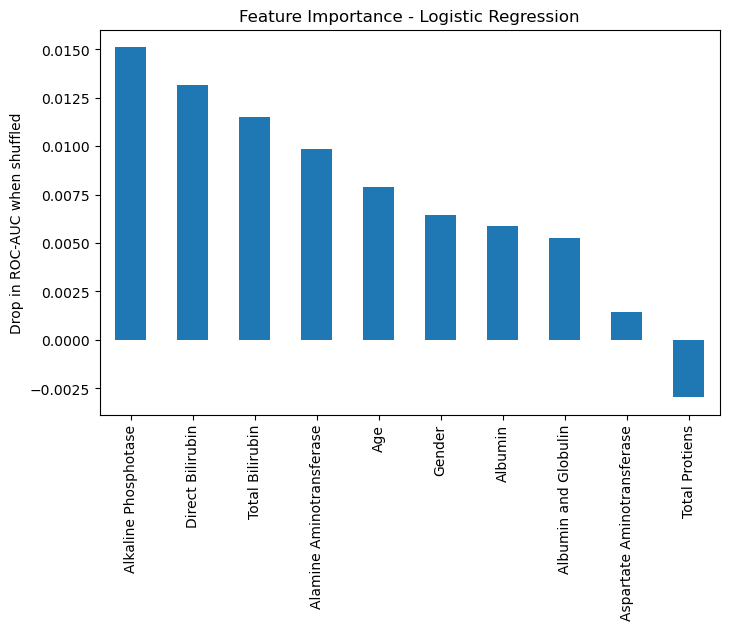

Alkaline Phosphotase          0.0151
Direct Bilirubin              0.0132
Total Bilirubin               0.0115
Alamine Aminotransferase      0.0098
Age                           0.0079
Gender                        0.0064
Albumin                       0.0059
Albumin and Globulin          0.0053
Aspartate Aminotransferase    0.0014
Total Protiens               -0.0030
dtype: float64

In [71]:
# Feature importance:

from sklearn.inspection import permutation_importance

final_name = 'Logistic Regression'        # change if you pick another model
final_model = tuned_models[final_name]

result = permutation_importance(final_model, x_test_scaled, y_test,
                                scoring='roc_auc', n_repeats=20, random_state=42)

importance = pd.Series(result.importances_mean, index=x.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importance.plot(kind='bar')
plt.title(f"Feature Importance - {final_name}")
plt.ylabel("Drop in ROC-AUC when shuffled")
plt.show()

importance.round(4)

### Feature importance (Logistic Regression, permutation importance on ROC-AUC)
- Most influential: Alkaline Phosphotase (0.015), Direct Bilirubin (0.013), Total Bilirubin (0.012), ALT (0.010),
  followed by Age (0.008), Gender (0.006), Albumin (0.006) and A/G ratio (0.005).
- AST (0.001) and Total Proteins (-0.003) contribute almost nothing; Total Proteins also showed no difference
  between classes in the EDA.
- Importance values are small because the model is heavily regularised and spreads weight across features;
  correlated pairs (Total/Direct Bilirubin 0.975, ALT/AST 0.84) share credit, so individual ranks are not stable.
- Consistently, bilirubin and liver-enzyme markers matter more than demographic variables, in line with clinical knowledge.

### Deployment
- The final model (Logistic Regression), scaler and threshold were saved with joblib and served through a Streamlit app
  with a single-patient form, a batch CSV tab that reports performance, and an adjustable threshold slider.
- The batch tab reproduces the notebook test results exactly (recall 0.840, ROC-AUC 0.828).
- The model's output is a risk score, not a calibrated probability. The app is a screening aid, not a diagnosis.

#### Comparison of Models evaluation metrics:

### Final Conclusion
- Seven classifiers were built and tuned on 570 records. Logistic Regression was selected: CV ROC-AUC 0.723, test
  ROC-AUC 0.828.
- With the threshold set to 0.46 it catches 84% of diseased patients (13 of 81 missed) and flags 48% of healthy
  patients (16 of 33), suitable as a first-stage screening aid.
- Performance is moderate because classes overlap heavily; complex models offered no benefit.
- Bilirubin, ALP and ALT were the most useful markers.

### Limitations and Future Work
- Small single-region dataset; 33 healthy patients in the test set, so metrics are uncertain. External validation
  on data from other hospitals is needed.
- Scores are not calibrated probabilities. Calibration, larger multi-centre data and extra features (for example the
  AST/ALT ratio) are the next steps.

### Report on Challenges Faced
| Challenge | Technique | Reason |
|---|---|---|
| 13 duplicate records | drop_duplicates | Prevents the same patient appearing in train and test |
| 4 missing values | Median imputation | Robust to skew and outliers |
| Skewed features and outliers | log1p, outliers kept | Extreme values are clinically meaningful |
| Class imbalance (71/29) | SMOTENC on training data only | Reduces bias towards the majority class without leakage |
| Different scales | StandardScaler fitted on train only | Needed for LR, SVM, KNN; avoids leakage |
| Multicollinearity | All features kept, regularised model | Clinically meaningful; trees and regularisation tolerate it |
| CV vs test mismatch | SMOTE inside each CV fold, shuffled folds | SMOTE before CV leaked synthetic samples and inflated CV AUC to 0.89 |
| Too many missed patients at threshold 0.5 | Threshold lowered to 0.46 using training data | Missed patients cost more than extra tests; recall rose from 0.67 to 0.84 |
| Small test set | Several metrics, differences treated as noise | One patient changes recall by about 1.2 points |

In [72]:
# Saving the model:

import joblib, sklearn
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import (confusion_matrix, recall_score, precision_score,
                             accuracy_score, f1_score, roc_auc_score)

final_model = tuned_models['Logistic Regression']
target_recall = 0.85            # catch at least 85% of diseased patients

# 1. Choose the threshold using TRAINING data only (SMOTE inside each fold)
pipe = Pipeline([('smote', SMOTENC(categorical_features=[1], random_state=42)),
                 ('clf', clone(final_model))])
oof = cross_val_predict(pipe, x_train_scaled, y_train,
                        cv=StratifiedKFold(5, shuffle=True, random_state=42),
                        method='predict_proba')[:, 1]

thr = max(t for t in np.unique(oof)
          if recall_score(y_train, (oof >= t).astype(int)) >= target_recall)
thr = float(np.floor(thr * 100) / 100)          # 2 decimals, same value the app will use

# 2. Check on the untouched test set
p = final_model.predict_proba(x_test_scaled)[:, 1]
pred = (p >= thr).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

print(f"Threshold: {thr}")
print(f"Missed patients: {fn} of {fn + tp}   | False alarms: {fp} of {fp + tn}")
print(f"Recall {recall_score(y_test, pred):.3f} | Precision {precision_score(y_test, pred):.3f} | "
      f"Accuracy {accuracy_score(y_test, pred):.3f} | F1 {f1_score(y_test, pred):.3f} | "
      f"ROC-AUC {roc_auc_score(y_test, p):.3f}")
print("Probability range on test set:", p.min().round(3), "-", p.max().round(3))

# 3. Save for the web app
import os
print(os.getcwd())

joblib.dump({
    'model': final_model,
    'scaler': scaler,
    'features': list(x.columns),
    'ag_median': 0.95,
    'threshold': thr,
    'metrics': {'Threshold': thr,
                'Accuracy': accuracy_score(y_test, pred),
                'Precision': precision_score(y_test, pred),
                'Recall': recall_score(y_test, pred),
                'F1': f1_score(y_test, pred),
                'ROC-AUC': roc_auc_score(y_test, p)},
    'sklearn_version': sklearn.__version__,
}, "liver_model.pkl")
print("Saved liver_model.pkl in", os.getcwd())

Threshold: 0.46
Missed patients: 13 of 81   | False alarms: 16 of 33
Recall 0.840 | Precision 0.810 | Accuracy 0.746 | F1 0.824 | ROC-AUC 0.828
Probability range on test set: 0.414 - 0.763
C:\Users\USER\Datamites Projects\liver_app
Saved liver_model.pkl in C:\Users\USER\Datamites Projects\liver_app


In [73]:
import os
print(os.getcwd())

print(os.path.exists('liver_model.pkl'), os.path.exists('sample_test_patients.csv'))
print(pd.read_csv('sample_test_patients.csv').shape)       # expect (114, 11)
print(joblib.load('liver_model.pkl')['metrics'])

C:\Users\USER\Datamites Projects\liver_app
True True
(114, 11)
{'Threshold': 0.46, 'Accuracy': 0.7456140350877193, 'Precision': 0.8095238095238095, 'Recall': 0.8395061728395061, 'F1': 0.8242424242424242, 'ROC-AUC': 0.8282828282828283}
